In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import configparser

print("Bibliotecas carregadas com sucesso!")
print("Pandas:", pd.__version__)

Bibliotecas carregadas com sucesso!
Pandas: 2.2.3


In [ ]:

url = (
    "https://raw.githubusercontent.com/"
    "petrobras/3W/main/dataset/dataset.ini"
)

resposta = requests.get(url, timeout=30)
resposta.raise_for_status()

config = configparser.ConfigParser()
config.read_string(resposta.text)

versao = config["VERSION"]["DATASET"]

print("Dataset:", versao)

if versao == "2.0.0":
    print("Versão solicitada pelo professor confirmada!")
else:
    print("Atenção: conferir a versão do dataset.")

Dataset: 2.0.0
Versão solicitada pelo professor confirmada!


In [ ]:

url_api = (
    "https://api.github.com/repos/"
    "petrobras/3W/contents/dataset/0"
)

resposta = requests.get(url_api, timeout=30)
resposta.raise_for_status()

arquivos = resposta.json()

arquivos_parquet = [
    arquivo for arquivo in arquivos
    if arquivo["name"].endswith(".parquet")
]

print("Arquivos Parquet encontrados:",
      len(arquivos_parquet))

print("\nPrimeiros 5 arquivos:")
for arquivo in arquivos_parquet[:5]:
    print(arquivo["name"])

Arquivos Parquet encontrados: 594

Primeiros 5 arquivos:
WELL-00001_20170201010207.parquet
WELL-00001_20170201060114.parquet
WELL-00001_20170201110124.parquet
WELL-00001_20170201160311.parquet
WELL-00001_20170201210228.parquet


In [ ]:

import io

# Selecionar o menor arquivo da lista
arquivo = min(
    arquivos_parquet,
    key=lambda x: x["size"]
)

nome_arquivo = arquivo["name"]

print("Arquivo selecionado:", nome_arquivo)
print("Tamanho em bytes:", arquivo["size"])

# Baixar o arquivo
resposta = requests.get(
    arquivo["download_url"],
    timeout=120
)

resposta.raise_for_status()

# Transformar os dados em uma tabela
df = pd.read_parquet(
    io.BytesIO(resposta.content)
)

# Mostrar as dimensoes da tabela
print("\nQuantidade de linhas e colunas:")
print(df.shape)

# Mostrar os nomes das colunas
print("\nColunas disponiveis:")
print(df.columns.tolist())

# Mostrar os primeiros registros
display(df.head())

Arquivo selecionado: WELL-00002_20131214190030.parquet
Tamanho em bytes: 88321

Quantidade de linhas e colunas:
(10771, 29)

Colunas disponiveis:
['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL', 'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL', 'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-CKP', 'P-MON-SDV-P', 'P-PDG', 'PT-P', 'P-TPT', 'QBS', 'QGL', 'T-JUS-CKP', 'T-MON-CKP', 'T-PDG', 'T-TPT', 'class', 'state']


,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,...,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,class,state
timestamp,,,,,,,,,,,,,,,,,,,,,
2013-12-14 19:00:30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,16538200.0,NaN,NaN,NaN,NaN,NaN,118.1071,<NA>,<NA>
2013-12-14 19:00:31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,16538200.0,NaN,NaN,NaN,NaN,NaN,118.1077,<NA>,<NA>
2013-12-14 19:00:32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,16538200.0,NaN,NaN,NaN,NaN,NaN,118.1083,<NA>,<NA>
2013-12-14 19:00:33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,16538200.0,NaN,NaN,NaN,NaN,NaN,118.1090,<NA>,<NA>
2013-12-14 19:00:34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,16538200.0,NaN,NaN,NaN,NaN,NaN,118.1096,<NA>,<NA>


In [ ]:

# Contar os valores validos de cada coluna
valores_validos = df.notna().sum()

# Calcular a porcentagem de dados validos
percentual_valido = (
    df.notna().mean() * 100
)

# Organizar os resultados em uma tabela
resumo = pd.DataFrame({
    "Valores_validos": valores_validos,
    "Percentual_valido": percentual_valido
})

# Ordenar da coluna mais preenchida
# para a menos preenchida
resumo = resumo.sort_values(
    by="Valores_validos",
    ascending=False
)

# Mostrar a tabela completa
display(resumo.round(2))

# Mostrar quantas colunas possuem dados
print(
    "Colunas com pelo menos um valor valido:",
    (resumo["Valores_validos"] > 0).sum()
)

# Verificar os rotulos de classificacao
print("\nValores da coluna class:")
print(df["class"].value_counts(dropna=False))

,Valores_validos,Percentual_valido
P-ANULAR,10771,100.00
P-PDG,10771,100.00
T-TPT,10771,100.00
P-TPT,10771,100.00
class,7171,66.58
state,7171,66.58
ESTADO-M2,0,0.00
ESTADO-SDV-P,0,0.00
ESTADO-PXO,0,0.00
ABER-CKP,0,0.00


Colunas com pelo menos um valor valido: 6

Valores da coluna class:
class
0       7171
<NA>    3600
Name: count, dtype: Int64


Inicio da serie: 2013-12-14 19:00:30
Fim da serie: 2013-12-14 22:00:00

Primeiro registro classificado:
2013-12-14 20:00:30

Classes identificadas:
<IntegerArray>
[0]
Length: 1, dtype: Int16


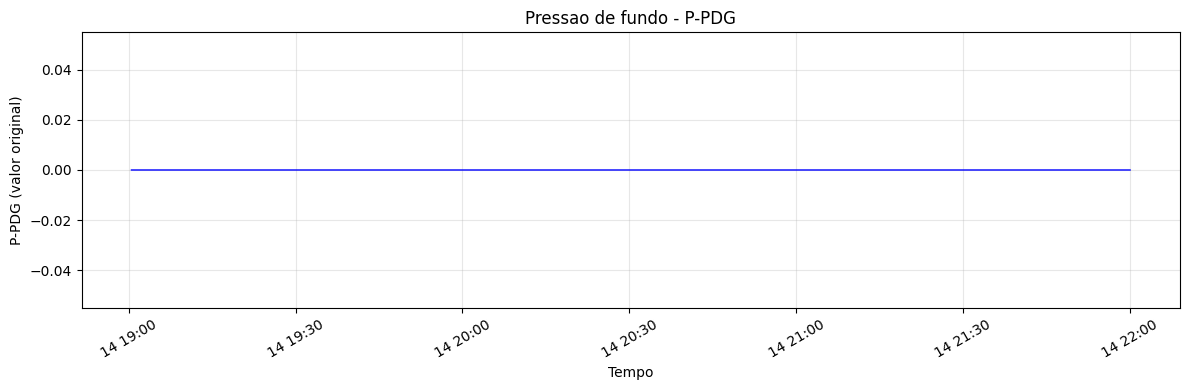

In [ ]:

# ETAPA 02 - Analise temporal da instancia

# Verificar o periodo registrado
print("Inicio da serie:", df.index.min())
print("Fim da serie:", df.index.max())

# Verificar o primeiro registro com classe conhecida
primeiro_rotulo = df["class"].first_valid_index()

print("\nPrimeiro registro classificado:")
print(primeiro_rotulo)

# Verificar quais classes aparecem
print("\nClasses identificadas:")
print(df["class"].dropna().unique())

# Criar o primeiro grafico de serie temporal
plt.figure(figsize=(12, 4))

plt.plot(
    df.index,
    df["P-PDG"],
    color="blue",
    linewidth=1
)

plt.title("Pressao de fundo - P-PDG")
plt.xlabel("Tempo")
plt.ylabel("P-PDG (valor original)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


In [ ]:

# SESSAO 02 - TAREFA 07
# Estatisticas descritivas dos sensores

sensores = [
    "P-ANULAR",
    "P-PDG",
    "P-TPT",
    "T-TPT"
]

estatisticas = pd.DataFrame({
    "Minimo": df[sensores].min(),
    "Maximo": df[sensores].max(),
    "Media": df[sensores].mean(),
    "Desvio_padrao": df[sensores].std(),
    "Valores_diferentes": df[sensores].nunique()
})

display(estatisticas.round(2))


,Minimo,Maximo,Media,Desvio_padrao,Valores_diferentes
P-ANULAR,16398550.00,16418500.00,16404565.94,8158.67,1294
P-PDG,0.00,0.00,0.00,0.00,1
P-TPT,16538200.00,16538200.00,16538200.00,0.00,1
T-TPT,118.04,118.12,118.10,0.01,684


Sensores com variacao:
['P-ANULAR', 'T-TPT']


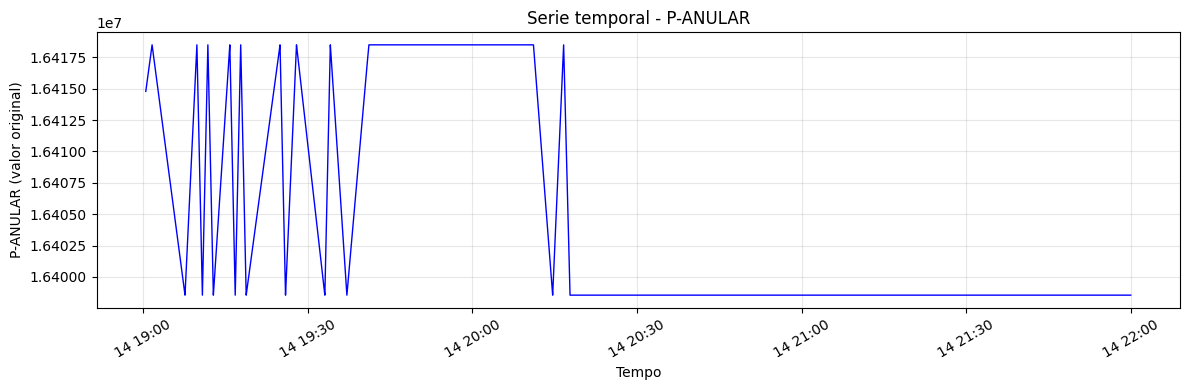

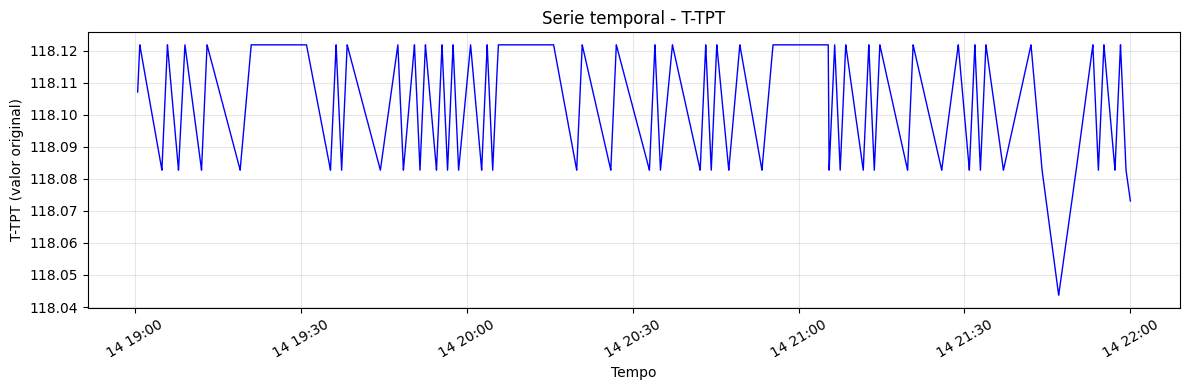

In [ ]:

# SESSAO 02 - TAREFA 08
# Graficos dos sensores com variacao

sensores_variaveis = [
    sensor for sensor in sensores
    if df[sensor].nunique() > 1
]

print("Sensores com variacao:")
print(sensores_variaveis)

for sensor in sensores_variaveis:

    plt.figure(figsize=(12, 4))

    plt.plot(
        df.index,
        df[sensor],
        color="blue",
        linewidth=1
    )

    plt.title(f"Serie temporal - {sensor}")
    plt.xlabel("Tempo")
    plt.ylabel(f"{sensor} (valor original)")

    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()
